# Review Title Generation with Encoder–Decoder Architectures

**Task.** Given the text of an Amazon food review, generate a short title for it.

```
Input : "this coffee is smooth and rich , i will buy it again ."
Output: "delicious coffee"
```

**Pipeline.** Text preprocessing → vocabulary → tokenization → embeddings → encoder → decoder → training → generation → evaluation.

**Experiment.** Three models that differ by one design decision at a time:

| Model | Encoder | Attention | Question answered |
|---|---|---|---|
| `lstm_baseline` | LSTM | no | Reference model with a fixed-size representation |
| `lstm_attention` | LSTM | yes | Does attention improve generation? |
| `bilstm_attention` | Bidirectional LSTM | yes | Does a bidirectional encoder add value? |

Two reference points that involve no learning are also evaluated, to show whether the neural models beat trivial strategies.

**How to run.** Select a GPU runtime, make the dataset available (section 2), then *Run all*. Outputs are written to `outputs/` and zipped at the end.

## 1. Setup and configuration

In [6]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rouge-score", "sacrebleu", "kagglehub"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'rouge-score', 'sacrebleu', 'kagglehub'], returncode=0)

In [7]:
import glob, hashlib, html, json, math, os, random, re, shutil, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

SMOKE_TEST = os.environ.get("NLP_SMOKE_TEST") == "1"  # small run used only to test the code

CFG = {
    "seed": 42,
    # Data
    "n_samples": 60_000,
    "min_src_tokens": 10,
    "max_src_tokens_filter": 200,  # longer reviews are dropped
    "max_src_len": 80,             # remaining reviews are truncated to this length
    "min_tgt_tokens": 2,
    "max_tgt_tokens": 10,
    "src_min_freq": 3,
    "tgt_min_freq": 3,
    "src_max_vocab": 20_000,
    "tgt_max_vocab": 8_000,
    # Model
    "emb_dim": 128,
    "hidden_dim": 256,  # size of the encoder memory; split across directions if bidirectional
    "n_layers": 1,
    "dropout": 0.3,
    # Training
    "batch_size": 128,
    "epochs": 15,
    "patience": 3,
    "lr": 1e-3,
    "clip": 1.0,
    "teacher_forcing": 1.0,
    # Generation
    "beam_size": 5,
    "beam_alpha": 0.7,
    "n_bootstrap": 1000,
}
RUN_TF_EXPERIMENT = False  # optional: also trains the best model with teacher forcing = 0.5
FORCE_RETRAIN = False      # True ignores existing checkpoints

if SMOKE_TEST:
    CFG.update(n_samples=3000, epochs=3, patience=2, batch_size=64, emb_dim=32, hidden_dim=64,
               n_bootstrap=100, beam_size=3)
    RUN_TF_EXPERIMENT = True

OUT = Path("outputs")
FIG, CKPT, RES = OUT / "figures", OUT / "checkpoints", OUT / "results"
for directory in (FIG, CKPT, RES):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
if DEVICE.type == "cpu" and not SMOKE_TEST:
    print("WARNING: no GPU detected. In Colab: Runtime > Change runtime type > GPU.")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(CFG["seed"])

# Consistent chart styling and one fixed colour per model
COLORS = {"lstm_baseline": "#2a78d6", "lstm_attention": "#eb6834", "bilstm_attention": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "axes.titlesize": 11, "axes.titleweight": "bold",
})

Device: cuda Tesla T4


## 2. Dataset

**Amazon Fine Food Reviews** (McAuley & Leskovec, 2013), distributed on Kaggle as `snap/amazon-fine-food-reviews`.

| Field | Role |
|---|---|
| `Text` | Input: the review written by the customer |
| `Summary` | Target: the title written by the same customer |
| `Score` | 1–5 stars: not given to the model, used only for the sentiment analysis |
| `ProductId` | Not given to the model, used to build a clean split |

**Getting the file.**
* **Kaggle:** *Add Input* → search for "Amazon Fine Food Reviews". It is detected automatically.
* **Colab:** nothing to do, `kagglehub` downloads it. If that fails, upload `Reviews.csv` next to the notebook.

In [8]:
def find_dataset():
    candidates = glob.glob("/kaggle/input/**/Reviews.csv", recursive=True) + glob.glob("Reviews.csv")
    if candidates:
        return candidates[0]
    try:
        import kagglehub
        return str(Path(kagglehub.dataset_download("snap/amazon-fine-food-reviews")) / "Reviews.csv")
    except Exception as error:
        raise FileNotFoundError("Download Reviews.csv from Kaggle and upload it next to this notebook.") from error

DATA_PATH = os.environ.get("NLP_DATA_PATH") or find_dataset()
raw = pd.read_csv(DATA_PATH, usecols=["ProductId", "Score", "Summary", "Text"])
print(f"Loaded {len(raw):,} rows from {DATA_PATH}")
raw.head(3)

Loaded 568,454 rows from /kaggle/input/amazon-fine-food-reviews/Reviews.csv


,ProductId,Score,Summary,Text
0,B001E4KFG0,5,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,B00813GRG4,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,B000LQOCH0,4,"""Delight"" says it all",This is a confection that has been around a fe...


## 3. Text preprocessing

Each step responds to a property of this dataset:

| Step | Why |
|---|---|
| Unescape HTML, remove tags and URLs | Reviews contain artefacts such as `<br />` and `&quot;` that carry no meaning |
| Lowercase | "Great", "GREAT" and "great" would otherwise be three separate tokens, each with less training data |
| Collapse repeated punctuation | "!!!!!" becomes "!" so punctuation does not inflate the vocabulary |
| Keep `. , ! ?` in reviews | Punctuation carries sentence structure and sentiment in the input |
| Remove punctuation from titles | The model should spend its capacity on words; ROUGE ignores punctuation anyway |
| Regex tokenizer keeping contractions | "don't" stays one token, which preserves negation |
| Remove exact duplicate reviews | The same review is often listed under several product variants. Keeping them would place identical examples in train and test |
| Length filters and truncation | Keeps RNN training tractable and removes one-word titles such as "Yum" |

In [9]:
TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
REPEAT_PUNCT_RE = re.compile(r"([.,!?])\1+")
SRC_TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[.,!?]")
TGT_TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")

def normalize(text):
    text = html.unescape(str(text))
    text = TAG_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = text.lower().replace("’", "'").replace("`", "'")
    return REPEAT_PUNCT_RE.sub(r"\1", text)

def tokenize_source(text):
    return SRC_TOKEN_RE.findall(normalize(text))

def tokenize_target(text):
    return TGT_TOKEN_RE.findall(normalize(text))

print(tokenize_source("I LOVE this!!! Don't buy the other brand.<br />Great &amp; cheap."))
print(tokenize_target("Great coffee!!!"))

['i', 'love', 'this', '!', "don't", 'buy', 'the', 'other', 'brand', '.', 'great', 'cheap', '.']
['great', 'coffee']


In [10]:
funnel = {"raw rows": len(raw)}
data = raw.dropna(subset=["Text", "Summary"]).copy()
funnel["both fields present"] = len(data)

data["norm_text"] = data["Text"].map(normalize)
data = data.drop_duplicates("norm_text").drop(columns="norm_text")
funnel["after removing duplicate reviews"] = len(data)

data["src_len"] = data["Text"].map(lambda t: len(tokenize_source(t)))
data["tgt_len"] = data["Summary"].map(lambda t: len(tokenize_target(t)))
data = data[data["src_len"].between(CFG["min_src_tokens"], CFG["max_src_tokens_filter"])
            & data["tgt_len"].between(CFG["min_tgt_tokens"], CFG["max_tgt_tokens"])]
funnel["after length filters"] = len(data)

data = data.sample(min(CFG["n_samples"], len(data)), random_state=CFG["seed"]).reset_index(drop=True)
funnel["after sampling"] = len(data)
data["src_tokens"] = data["Text"].map(tokenize_source)  # kept for sampled rows only, to save memory
data["tgt_tokens"] = data["Summary"].map(tokenize_target)

funnel_df = pd.DataFrame({"rows": funnel})
funnel_df.to_csv(RES / "dataset_funnel.csv")
funnel_df

,rows
raw rows,568454
both fields present,568427
after removing duplicate reviews,393552
after length filters,317758
after sampling,60000


### Train / validation / test split

The split is 80/10/10 **by product**: all reviews of a product fall in the same set. With a random split, a test review could share its product, and often its vocabulary, with training reviews, which would overestimate performance on new inputs.

The sizes are therefore approximately, not exactly, 80/10/10. Validation is used for early stopping and model selection. Test is only used to report final results.

In [11]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=CFG["seed"])
train_idx, holdout_idx = next(outer.split(data, groups=data["ProductId"]))
holdout = data.iloc[holdout_idx]
inner = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=CFG["seed"])
val_rel, test_rel = next(inner.split(holdout, groups=holdout["ProductId"]))

train_df = data.iloc[train_idx].reset_index(drop=True)
val_df = holdout.iloc[val_rel].reset_index(drop=True)
test_df = holdout.iloc[test_rel].reset_index(drop=True)
splits = {"train": train_df, "validation": val_df, "test": test_df}

assert not set(train_df.ProductId) & set(test_df.ProductId)
assert not set(train_df.ProductId) & set(val_df.ProductId)
assert not set(val_df.ProductId) & set(test_df.ProductId)

def polarity(score):
    return "positive" if score >= 4 else "negative" if score <= 2 else "neutral"

for frame in splits.values():
    frame["polarity"] = frame["Score"].map(polarity)

stats = pd.DataFrame({name: {
    "reviews": len(f), "products": f.ProductId.nunique(),
    "mean review tokens": round(f.src_len.mean(), 1), "median review tokens": f.src_len.median(),
    "share truncated": round((f.src_len > CFG["max_src_len"]).mean(), 3),
    "mean title tokens": round(f.tgt_len.mean(), 2),
    "% positive (4-5★)": round(100 * (f.polarity == "positive").mean(), 1),
    "% neutral (3★)": round(100 * (f.polarity == "neutral").mean(), 1),
    "% negative (1-2★)": round(100 * (f.polarity == "negative").mean(), 1),
} for name, f in splits.items()})
stats.to_csv(RES / "dataset_stats.csv")
stats

,train,validation,test
reviews,47762.000,6137.000,6101.000
products,20497.000,2562.000,2563.000
mean review tokens,71.700,73.300,72.000
median review tokens,60.000,61.000,60.000
share truncated,0.338,0.347,0.339
mean title tokens,4.110,4.100,4.120
% positive (4-5★),78.600,78.800,78.900
% neutral (3★),7.300,8.300,7.400
% negative (1-2★),14.100,13.000,13.700


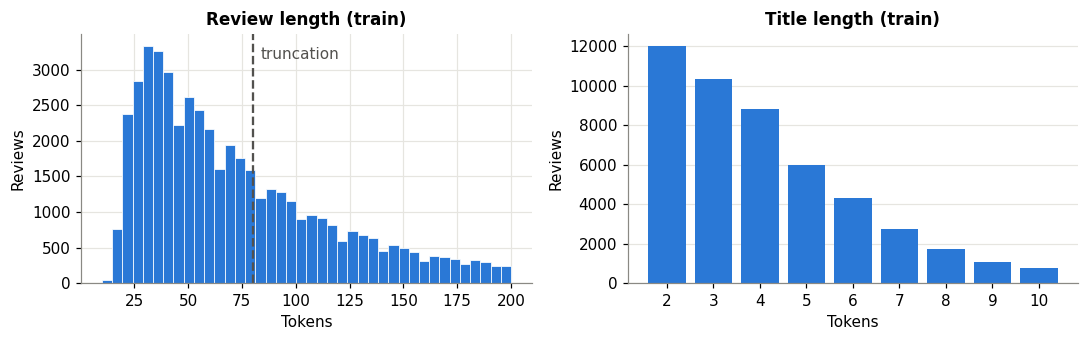

,title,count,% of train
0,great product,404,0.85
1,love it,257,0.54
2,good stuff,198,0.41
3,the best,181,0.38
4,great coffee,157,0.33
5,very good,122,0.26
6,great stuff,118,0.25
7,great taste,110,0.23
8,great tea,106,0.22
9,excellent product,98,0.21


In [12]:
top_titles = Counter(" ".join(t) for t in train_df.tgt_tokens)
top_titles_df = pd.DataFrame(top_titles.most_common(15), columns=["title", "count"])
top_titles_df["% of train"] = (100 * top_titles_df["count"] / len(train_df)).round(2)
top_titles_df.to_csv(RES / "top_train_titles.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(train_df.src_len, bins=40, color=COLORS["lstm_baseline"], edgecolor="white", linewidth=0.5)
axes[0].axvline(CFG["max_src_len"], color="#52514e", linestyle="--", linewidth=1.5)
axes[0].annotate("truncation", (CFG["max_src_len"], axes[0].get_ylim()[1] * 0.9), xytext=(5, 0),
                 textcoords="offset points", color="#52514e")
axes[0].set(title="Review length (train)", xlabel="Tokens", ylabel="Reviews")
counts = train_df.tgt_len.value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color=COLORS["lstm_baseline"], width=0.8)
axes[1].set(title="Title length (train)", xlabel="Tokens", ylabel="Reviews", xticks=counts.index)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "length_distributions.png"); plt.show()
top_titles_df.head(10)

## 4. Vocabulary and numerical representation

Reviews and titles each have their own vocabulary, **built on the training set only** so that no information leaks from validation or test.

| Token | ID | Role |
|---|---|---|
| `<PAD>` | 0 | Fills sequences to a common length. Ignored by the embedding, the attention and the loss |
| `<UNK>` | 1 | Replaces any word below the frequency threshold or unseen in training |
| `<SOS>` | 2 | First decoder input, tells it to start generating |
| `<EOS>` | 3 | Target end marker. Generating it stops the decoder |

Title vocabulary is smaller than review vocabulary because titles use a narrower set of words, and every extra word adds a column to the output layer.

In [13]:
PAD, UNK, SOS, EOS = 0, 1, 2, 3
SPECIALS = ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]

class Vocabulary:
    def __init__(self, token_lists, min_freq, max_size):
        counts = Counter(token for tokens in token_lists for token in tokens)
        kept = [t for t, c in counts.most_common(max_size - len(SPECIALS)) if c >= min_freq]
        self.itos = SPECIALS + kept
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        total = sum(counts.values())
        self.coverage = sum(counts[t] for t in kept) / max(total, 1)
        self.n_types_seen = len(counts)

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, UNK) for t in tokens]

    def decode(self, ids):
        words = []
        for i in ids:
            if i == EOS:
                break
            if i not in (PAD, SOS):
                words.append(self.itos[i])
        return words

src_vocab = Vocabulary(train_df.src_tokens, CFG["src_min_freq"], CFG["src_max_vocab"])
tgt_vocab = Vocabulary(train_df.tgt_tokens, CFG["tgt_min_freq"], CFG["tgt_max_vocab"])

def unk_rate(frame, column, vocab):
    tokens = [t for seq in frame[column] for t in seq]
    return sum(t not in vocab.stoi for t in tokens) / max(len(tokens), 1)

vocab_stats = pd.DataFrame({
    "review vocabulary": {"size": len(src_vocab), "word types in train": src_vocab.n_types_seen,
                          "train token coverage": round(src_vocab.coverage, 4),
                          "test <UNK> rate": round(unk_rate(test_df, "src_tokens", src_vocab), 4)},
    "title vocabulary": {"size": len(tgt_vocab), "word types in train": tgt_vocab.n_types_seen,
                         "train token coverage": round(tgt_vocab.coverage, 4),
                         "test <UNK> rate": round(unk_rate(test_df, "tgt_tokens", tgt_vocab), 4)},
})
vocab_stats.to_csv(RES / "vocabulary_stats.csv")

example = test_df.iloc[0]
print("Review tokens:", example.src_tokens[:12])
print("Review IDs   :", src_vocab.encode(example.src_tokens[:12]))
print("Title tokens :", example.tgt_tokens)
print("Title IDs    :", [SOS] + tgt_vocab.encode(example.tgt_tokens) + [EOS])
vocab_stats

Review tokens: ['i', 'have', 'been', 'buying', 'gumballs', 'for', 'my', 'bank', 'for', 'the', 'grandkids', 'for']
Review IDs   : [7, 21, 87, 205, 5464, 15, 17, 3694, 15, 5, 3725, 15]
Title tokens : ['hollow', 'gum', 'balls']
Title IDs    : [2, 1, 176, 1420, 3]


,review vocabulary,title vocabulary
size,16429.0000,4342.0000
word types in train,38329.0000,11763.0000
train token coverage,0.9922,0.9544
test <UNK> rate,0.0106,0.0609


In [14]:
class TitleDataset(Dataset):
    def __init__(self, frame):
        self.src = [torch.tensor(src_vocab.encode(s[:CFG["max_src_len"]])) for s in frame.src_tokens]
        self.tgt = [torch.tensor([SOS] + tgt_vocab.encode(t) + [EOS]) for t in frame.tgt_tokens]

    def __len__(self):
        return len(self.src)

    def __getitem__(self, index):
        return self.src[index], self.tgt[index]

def collate(batch):
    src, tgt = zip(*batch)
    lengths = torch.tensor([len(s) for s in src])
    return (pad_sequence(src, batch_first=True, padding_value=PAD), lengths,
            pad_sequence(tgt, batch_first=True, padding_value=PAD))

def loader(frame, shuffle=False):
    return DataLoader(TitleDataset(frame), batch_size=CFG["batch_size"], shuffle=shuffle, collate_fn=collate)

train_loader, val_loader, test_loader = loader(train_df, True), loader(val_df), loader(test_df)

## 5. Model architecture

**Encoder.** Embedding → LSTM. It returns the state at every position (the memory, used by attention) and a final state summarising the review. Sequences are packed so the LSTM stops at each review's true last word instead of reading padding. The bidirectional encoder concatenates both directions. It uses `hidden_dim / 2` units per direction, so every encoder produces vectors of the same size and the comparison is not biased by a larger memory.

**Bridge.** A linear layer with `tanh` maps the encoder's final state to the decoder's initial state.

**Attention (Bahdanau).** A single final vector must summarise a whole review. Attention instead lets the decoder consult every review position at every step:

$$e_{t,i} = v^\top \tanh(W_s s_{t-1} + W_h h_i), \qquad \alpha_{t,i} = \mathrm{softmax}(e_{t,i}), \qquad c_t = \sum_i \alpha_{t,i} h_i$$

Padding positions receive a score of $-\infty$ so their weight is exactly 0.

**Decoder.** One step at a time, it receives the previous token and, with attention, the context $c_t$. Its hidden state goes through a linear layer that gives one score per title word. Softmax is applied inside the cross-entropy loss during training, and at generation time when probabilities are needed.

In [15]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, n_layers, bidirectional, dropout):
        super().__init__()
        self.bidirectional, self.n_layers = bidirectional, n_layers
        units = hidden_dim // 2 if bidirectional else hidden_dim
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = nn.LSTM(emb_dim, units, n_layers, batch_first=True, bidirectional=bidirectional,
                           dropout=dropout if n_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)

    def _merge(self, state):
        # (layers * directions, batch, units) -> (layers, batch, hidden_dim)
        if not self.bidirectional:
            return state
        return torch.cat([state[0::2], state[1::2]], dim=-1)

    def forward(self, src, lengths):
        embedded = self.dropout(self.embedding(src))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        outputs, (h, c) = self.rnn(packed)
        outputs, _ = pad_packed_sequence(outputs, batch_first=True, total_length=src.size(1))
        return outputs, (self._merge(h), self._merge(c))


class BahdanauAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.W_s = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_h = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, query, memory, mask):
        scores = self.v(torch.tanh(self.W_s(query).unsqueeze(1) + self.W_h(memory))).squeeze(-1)
        weights = torch.softmax(scores.masked_fill(~mask, float("-inf")), dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, n_layers, use_attention, dropout):
        super().__init__()
        self.use_attention = use_attention
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.attention = BahdanauAttention(hidden_dim) if use_attention else None
        rnn_input = emb_dim + hidden_dim if use_attention else emb_dim
        self.rnn = nn.LSTM(rnn_input, hidden_dim, n_layers, batch_first=True,
                           dropout=dropout if n_layers > 1 else 0.0)
        out_input = hidden_dim * 2 + emb_dim if use_attention else hidden_dim
        self.out = nn.Linear(out_input, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def step(self, previous, state, memory, mask):
        embedded = self.dropout(self.embedding(previous))
        weights = None
        if self.use_attention:
            context, weights = self.attention(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        else:
            rnn_input = embedded
        output, state = self.rnn(rnn_input.unsqueeze(1), state)
        output = output.squeeze(1)
        features = torch.cat([output, context, embedded], dim=-1) if self.use_attention else output
        return self.out(self.dropout(features)), state, weights


class Seq2Seq(nn.Module):
    def __init__(self, bidirectional, use_attention):
        super().__init__()
        h = CFG["hidden_dim"]
        self.encoder = Encoder(len(src_vocab), CFG["emb_dim"], h, CFG["n_layers"], bidirectional, CFG["dropout"])
        self.bridge_h = nn.Linear(h, h)
        self.bridge_c = nn.Linear(h, h)
        self.decoder = Decoder(len(tgt_vocab), CFG["emb_dim"], h, CFG["n_layers"], use_attention, CFG["dropout"])

    def encode(self, src, lengths):
        memory, (h, c) = self.encoder(src, lengths)
        state = (torch.tanh(self.bridge_h(h)), torch.tanh(self.bridge_c(c)))
        return memory, src != PAD, state

    def forward(self, src, lengths, tgt, teacher_forcing):
        memory, mask, state = self.encode(src, lengths)
        previous, all_logits = tgt[:, 0], []
        for t in range(tgt.size(1) - 1):
            logits, state, _ = self.decoder.step(previous, state, memory, mask)
            all_logits.append(logits)
            if teacher_forcing >= 1.0:
                previous = tgt[:, t + 1]
            else:
                use_truth = torch.rand(tgt.size(0), device=tgt.device) < teacher_forcing
                previous = torch.where(use_truth, tgt[:, t + 1], logits.argmax(-1))
        return torch.stack(all_logits, dim=1)

MODEL_SPECS = {
    "lstm_baseline": {"bidirectional": False, "use_attention": False},
    "lstm_attention": {"bidirectional": False, "use_attention": True},
    "bilstm_attention": {"bidirectional": True, "use_attention": True},
}

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

param_counts = {name: count_parameters(Seq2Seq(**spec)) for name, spec in MODEL_SPECS.items()}
print(Seq2Seq(**MODEL_SPECS["lstm_attention"]))
pd.Series(param_counts, name="trainable parameters").to_frame()

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(16429, 128, padding_idx=0)
    (rnn): LSTM(128, 256, batch_first=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
  (bridge_h): Linear(in_features=256, out_features=256, bias=True)
  (bridge_c): Linear(in_features=256, out_features=256, bias=True)
  (decoder): Decoder(
    (embedding): Embedding(4342, 128, padding_idx=0)
    (attention): BahdanauAttention(
      (W_s): Linear(in_features=256, out_features=256, bias=False)
      (W_h): Linear(in_features=256, out_features=256, bias=False)
      (v): Linear(in_features=256, out_features=1, bias=False)
    )
    (rnn): LSTM(384, 256, batch_first=True)
    (out): Linear(in_features=640, out_features=4342, bias=True)
    (dropout): Dropout(p=0.3, inplace=False)
  )
)


,trainable parameters
lstm_baseline,4696694
lstm_attention,6757494
bilstm_attention,6626422


## 6. Training

* **Loss:** token-level cross-entropy, ignoring `<PAD>`.
* **Optimizer:** Adam, with the learning rate halved when validation loss stops improving.
* **Gradient clipping** at norm 1 prevents the exploding gradients RNNs are prone to.
* **Teacher forcing:** the decoder receives the true previous token (ratio 1.0). Train and validation losses are then measured under the same conditions, so their curves can be compared directly. Generation has no true tokens to rely on, which is why validation loss alone is not enough and generated text is evaluated too.
* **Early stopping:** training stops after `patience` epochs without improvement and the best checkpoint is restored.

An existing checkpoint is reused if it was trained with the same configuration, so a Colab disconnection does not lose finished models.

In [16]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")

def run_epoch(model, data_loader, optimizer=None, teacher_forcing=1.0):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens, correct = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for src, lengths, tgt in data_loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            logits = model(src, lengths, tgt, teacher_forcing)
            target = tgt[:, 1:]
            loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
            tokens = (target != PAD).sum().item()
            if training:
                optimizer.zero_grad()
                (loss / tokens).backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["clip"])
                optimizer.step()
            total_loss += loss.item()
            total_tokens += tokens
            correct += ((logits.argmax(-1) == target) & (target != PAD)).sum().item()
    return total_loss / total_tokens, correct / total_tokens

fingerprint = {**CFG, "n_bootstrap": 0, "beam_size": 0, "beam_alpha": 0, "vocab": [len(src_vocab), len(tgt_vocab)]}
CFG_HASH = hashlib.md5(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:10]

def train_model(name, spec, teacher_forcing):
    path = CKPT / f"{name}.pt"
    set_seed(CFG["seed"])
    model = Seq2Seq(**spec).to(DEVICE)
    if path.exists() and not FORCE_RETRAIN:
        saved = torch.load(path, map_location=DEVICE)
        if saved["cfg_hash"] == CFG_HASH:
            model.load_state_dict(saved["state"])
            print(f"{name}: reusing existing checkpoint")
            return model, saved["history"]

    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)
    history, best_loss, stale, best_state = [], float("inf"), 0, None
    print(f"\n=== {name} | {count_parameters(model):,} parameters | teacher forcing {teacher_forcing} ===")
    for epoch in range(1, CFG["epochs"] + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, optimizer, teacher_forcing)
        with torch.no_grad():
            val_loss, val_acc = run_epoch(model, val_loader)
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_acc": train_acc, "val_acc": val_acc, "lr": lr, "seconds": time.time() - start})
        print(f"epoch {epoch:2d} | train {train_loss:.3f} | val {val_loss:.3f} | "
              f"val acc {val_acc:.3f} | lr {lr:.5f} | {time.time() - start:.0f}s")
        if val_loss < best_loss:
            best_loss, stale = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= CFG["patience"]:
                print(f"Early stopping at epoch {epoch}")
                break
    model.load_state_dict(best_state)
    torch.save({"state": best_state, "history": history, "cfg_hash": CFG_HASH}, path)
    return model, history

models, histories = {}, {}
for name, spec in MODEL_SPECS.items():
    models[name], histories[name] = train_model(name, spec, CFG["teacher_forcing"])
pd.concat([pd.DataFrame(h).assign(model=n) for n, h in histories.items()]).to_csv(RES / "training_history.csv", index=False)


=== lstm_baseline | 4,696,694 parameters | teacher forcing 1.0 ===
epoch  1 | train 5.290 | val 4.761 | val acc 0.265 | lr 0.00100 | 13s
epoch  2 | train 4.778 | val 4.514 | val acc 0.284 | lr 0.00100 | 13s
epoch  3 | train 4.570 | val 4.388 | val acc 0.292 | lr 0.00100 | 12s
epoch  4 | train 4.430 | val 4.308 | val acc 0.297 | lr 0.00100 | 12s
epoch  5 | train 4.323 | val 4.259 | val acc 0.303 | lr 0.00100 | 12s
epoch  6 | train 4.237 | val 4.220 | val acc 0.307 | lr 0.00100 | 12s
epoch  7 | train 4.164 | val 4.189 | val acc 0.311 | lr 0.00100 | 12s
epoch  8 | train 4.095 | val 4.160 | val acc 0.314 | lr 0.00100 | 11s
epoch  9 | train 4.030 | val 4.136 | val acc 0.317 | lr 0.00100 | 12s
epoch 10 | train 3.971 | val 4.113 | val acc 0.318 | lr 0.00100 | 12s
epoch 11 | train 3.907 | val 4.077 | val acc 0.322 | lr 0.00100 | 12s
epoch 12 | train 3.846 | val 4.060 | val acc 0.325 | lr 0.00100 | 12s
epoch 13 | train 3.794 | val 4.040 | val acc 0.327 | lr 0.00100 | 12s
epoch 14 | train 3.741

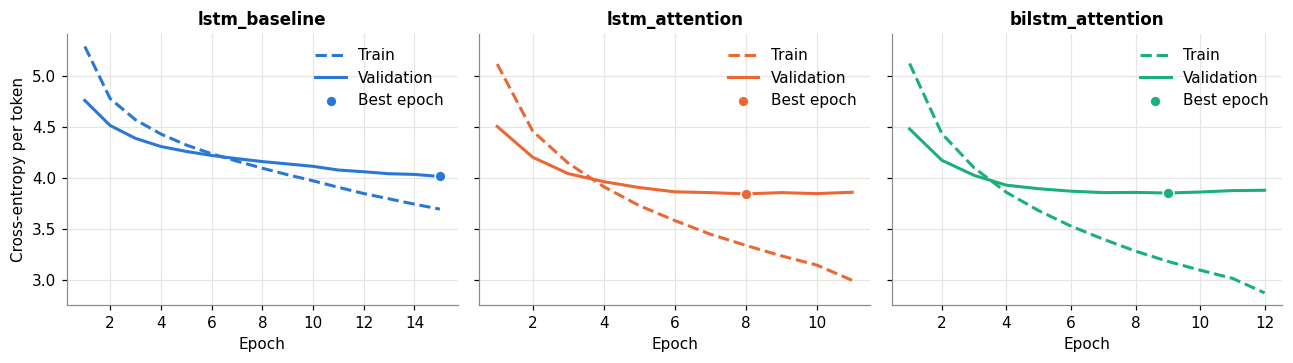

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    h = pd.DataFrame(history)
    ax.plot(h.epoch, h.train_loss, color=COLORS[name], linestyle="--", label="Train")
    ax.plot(h.epoch, h.val_loss, color=COLORS[name], label="Validation")
    best = h.loc[h.val_loss.idxmin()]
    ax.scatter([best.epoch], [best.val_loss], s=50, color=COLORS[name], edgecolor="white", zorder=3, label="Best epoch")
    ax.set(title=name, xlabel="Epoch")
    ax.legend(frameon=False)
axes[0].set_ylabel("Cross-entropy per token")
fig.tight_layout(); fig.savefig(FIG / "learning_curves.png"); plt.show()

## 7. Generation

**Greedy decoding** picks the most probable word at each step. It is fast, but an early choice can never be undone.

**Beam search** keeps the `k` best partial titles at each step and returns the best one by length-normalised log-probability: $\frac{\sum \log p}{\text{length}^{\alpha}}$.

**Stopping:** `<EOS>` generated, or the maximum title length reached.

`<UNK>`, `<PAD>` and `<SOS>` are never allowed as output, and `<EOS>` is blocked at the first step so a title cannot be empty.

In [18]:
FORBIDDEN = [PAD, UNK, SOS]
MAX_GEN_LEN = CFG["max_tgt_tokens"] + 1  # including <EOS>

@torch.no_grad()
def greedy_batch(model, src, lengths, max_len=MAX_GEN_LEN, return_attention=False):
    model.eval()
    memory, mask, state = model.encode(src, lengths)
    previous = torch.full((src.size(0),), SOS, device=src.device)
    outputs, attention = [], []
    for t in range(max_len):
        logits, state, weights = model.decoder.step(previous, state, memory, mask)
        logits[:, FORBIDDEN] = float("-inf")
        if t == 0:
            logits[:, EOS] = float("-inf")
        previous = logits.argmax(-1)
        outputs.append(previous)
        if weights is not None:
            attention.append(weights)
    outputs = torch.stack(outputs, dim=1)
    if return_attention:
        return outputs, torch.stack(attention, dim=1) if attention else None
    return outputs

@torch.no_grad()
def beam_batch(model, src, lengths, k, alpha, max_len=MAX_GEN_LEN):
    model.eval()
    batch = src.size(0)
    memory, mask, state = model.encode(src, lengths)
    memory = memory.repeat_interleave(k, dim=0)
    mask = mask.repeat_interleave(k, dim=0)
    state = tuple(s.repeat_interleave(k, dim=1) for s in state)
    sequences = torch.full((batch * k, 1), SOS, device=src.device)
    scores = torch.full((batch, k), -1e9, device=src.device)
    scores[:, 0] = 0.0  # only the first beam is alive at the start
    finished = torch.zeros(batch * k, dtype=torch.bool, device=src.device)
    for t in range(max_len):
        logits, state, _ = model.decoder.step(sequences[:, -1], state, memory, mask)
        log_probs = torch.log_softmax(logits, dim=-1)
        log_probs[:, FORBIDDEN] = float("-inf")
        if t == 0:
            log_probs[:, EOS] = float("-inf")
        # A finished beam can only continue with <PAD>, at no cost
        log_probs[finished] = float("-inf")
        log_probs[finished, PAD] = 0.0
        vocab = log_probs.size(-1)
        totals = (scores.view(-1, 1) + log_probs).view(batch, -1)
        scores, flat_index = totals.topk(k, dim=1)
        parent = flat_index // vocab
        token = flat_index % vocab
        parent = (parent + torch.arange(batch, device=src.device).unsqueeze(1) * k).view(-1)
        sequences = torch.cat([sequences[parent], token.view(-1, 1)], dim=1)
        state = tuple(s[:, parent] for s in state)
        finished = finished[parent] | (token.view(-1) == EOS)
        if finished.all():
            break
    generated = sequences[:, 1:]
    title_len = (generated != PAD).sum(dim=1).clamp(min=1).float().view(batch, k)
    best = (scores / title_len.pow(alpha)).argmax(dim=1)
    return generated.view(batch, k, -1)[torch.arange(batch), best]

def generate_titles(model, data_loader, method="greedy"):
    titles = []
    for src, lengths, _ in data_loader:
        src = src.to(DEVICE)
        if method == "greedy":
            ids = greedy_batch(model, src, lengths)
        else:
            ids = beam_batch(model, src, lengths, CFG["beam_size"], CFG["beam_alpha"])
        titles.extend(tgt_vocab.decode(row) for row in ids.tolist())
    return titles

# Consistency check: a beam of size 1 must give the same output as greedy decoding
src_check, len_check, _ = next(iter(val_loader))
src_check = src_check.to(DEVICE)
reference_model = models["lstm_attention"]
assert ([tgt_vocab.decode(r) for r in greedy_batch(reference_model, src_check, len_check).tolist()]
        == [tgt_vocab.decode(r) for r in beam_batch(reference_model, src_check, len_check, 1, 0.0).tolist()])
print("Beam size 1 matches greedy decoding")

# Consistency check: padding must not change the output
for check_model in models.values():
    short, long_ = TitleDataset(test_df.iloc[:1])[0][0], max(TitleDataset(test_df.iloc[:200]).src, key=len)
    alone = greedy_batch(check_model, short.unsqueeze(0).to(DEVICE), torch.tensor([len(short)]))
    padded = pad_sequence([short, long_], batch_first=True, padding_value=PAD).to(DEVICE)
    together = greedy_batch(check_model, padded, torch.tensor([len(short), len(long_)]))
    assert alone[0].tolist() == together[0].tolist()
print("Padding does not change the generated titles")

def generate_title(model, review, method="greedy"):
    # Generates a title for a review that is outside the dataset
    ids = src_vocab.encode(tokenize_source(review)[:CFG["max_src_len"]])
    src = torch.tensor([ids], device=DEVICE)
    lengths = torch.tensor([len(ids)])
    output = greedy_batch(model, src, lengths) if method == "greedy" else beam_batch(model, src, lengths, CFG["beam_size"], CFG["beam_alpha"])
    return " ".join(tgt_vocab.decode(output[0].tolist()))

Beam size 1 matches greedy decoding
Padding does not change the generated titles


## 8. Evaluation

No single metric is enough for this task, so several are combined:

| Metric | Measures | Why it is used |
|---|---|---|
| **ROUGE-1 / ROUGE-2 / ROUGE-L (F1)** | Word, bigram and longest-subsequence overlap with the reference title | Standard for summarisation. **ROUGE-1 is the primary metric**, because titles are short |
| **BLEU-2 / BLEU-4** | N-gram precision with a length penalty, corpus level | Complements ROUGE. BLEU-2 stops at bigrams and suits short titles. BLEU-4, the usual version, is shown for reference and is very low when outputs have fewer than 4 words |
| **Exact match** | Output identical to the reference | Strict check, expected to be low since many titles are valid |
| **Perplexity** | How well the model predicts reference words | Language-model quality under teacher forcing, independent of decoding |
| **Token accuracy** | Share of correctly predicted next tokens | Basic diagnostic under teacher forcing |
| **Distinct titles / most frequent title share** | Output diversity | Detects a model that repeats a generic title, which overlap metrics can reward |
| **Sentiment agreement** | Whether the title's sentiment matches the star rating | Task-specific: a title should not reverse the opinion of the review |

**How sentiment agreement works.** A simple classifier (TF-IDF + logistic regression) is trained on *train titles* labelled by stars, and is only an evaluation tool. 3-star reviews are excluded because they have no clear polarity. Positive reviews are the large majority, so **balanced accuracy** is the score to read: always outputting a positive title scores 0.5.

**Reference titles are never replaced by `<UNK>` for evaluation:** a target word missing from the vocabulary counts against the model, as it should.

In [19]:
sent_train = train_df[train_df.polarity != "neutral"]
sentiment_clf = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
sentiment_clf.fit([" ".join(t) for t in sent_train.tgt_tokens], sent_train.polarity)

BLEU2 = BLEU(max_ngram_order=2, tokenize="none", force=True)
BLEU4 = BLEU(max_ngram_order=4, tokenize="none", force=True)
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def per_example_scores(predictions, frame):
    rows = []
    for pred, ref in zip(predictions, frame.tgt_tokens):
        p, r = " ".join(pred), " ".join(ref)
        s = scorer.score(r, p)
        rows.append({"rouge1": s["rouge1"].fmeasure, "rouge2": s["rouge2"].fmeasure,
                     "rougeL": s["rougeL"].fmeasure, "exact": float(p == r)})
    return pd.DataFrame(rows)

def sentiment_scores(titles, frame):
    keep = (frame.polarity != "neutral").values
    texts = [" ".join(t) for t, k in zip(titles, keep) if k]
    predicted = sentiment_clf.predict(texts)
    truth = frame.polarity.values[keep]
    return float((predicted == truth).mean()), float(balanced_accuracy_score(truth, predicted))

def evaluate_titles(predictions, frame):
    scores = per_example_scores(predictions, frame)
    joined = [" ".join(p) for p in predictions]
    refs = [" ".join(t) for t in frame.tgt_tokens]
    agree, balanced = sentiment_scores(predictions, frame)
    top_share = Counter(joined).most_common(1)[0][1] / len(joined)
    summary = {
        "ROUGE-1": scores.rouge1.mean(), "ROUGE-2": scores.rouge2.mean(), "ROUGE-L": scores.rougeL.mean(),
        "BLEU-2": BLEU2.corpus_score(joined, [refs]).score, "BLEU-4": BLEU4.corpus_score(joined, [refs]).score,
        "exact match": scores.exact.mean(), "mean length": np.mean([len(p) for p in predictions]),
        "distinct titles": len(set(joined)) / len(joined), "top title share": top_share,
        "sentiment agreement": agree, "sentiment balanced acc": balanced,
    }
    return summary, scores

def language_metrics(model, data_loader):
    with torch.no_grad():
        loss, accuracy = run_epoch(model, data_loader)
    return {"loss": loss, "perplexity": math.exp(loss), "token accuracy": accuracy}

# Non-neural reference points
MOST_COMMON_TITLE = top_titles.most_common(1)[0][0].split()
def constant_titles(frame): return [MOST_COMMON_TITLE for _ in range(len(frame))]
def lead_titles(frame, n=4): return [[t for t in s if t not in ".,!?"][:n] for s in frame.src_tokens]

print("Most frequent train title:", " ".join(MOST_COMMON_TITLE))
print(f"Sentiment classifier on validation reference titles (balanced accuracy): "
      f"{sentiment_scores(list(val_df.tgt_tokens), val_df)[1]:.3f}")

Most frequent train title: great product
Sentiment classifier on validation reference titles (balanced accuracy): 0.850


In [20]:
LOADERS = {"validation": val_loader, "test": test_loader}
FRAMES = {"validation": val_df, "test": test_df}
results, per_example, generated = [], {}, {}

for split, frame in FRAMES.items():
    for label, predictions in [("reference: most frequent title", constant_titles(frame)),
                               ("reference: first 4 words", lead_titles(frame))]:
        summary, _ = evaluate_titles(predictions, frame)
        results.append({"split": split, "model": label, "decoding": "-", **summary})
    # Human reference titles give the best sentiment agreement the classifier can reach
    agree, balanced = sentiment_scores(list(frame.tgt_tokens), frame)
    results.append({"split": split, "model": "human titles (sentiment only)", "decoding": "-",
                    "sentiment agreement": agree, "sentiment balanced acc": balanced})
    for name, model in models.items():
        predictions = generate_titles(model, LOADERS[split])
        summary, scores = evaluate_titles(predictions, frame)
        results.append({"split": split, "model": name, "decoding": "greedy",
                        **summary, **language_metrics(model, LOADERS[split])})
        generated[(split, name, "greedy")] = predictions
        per_example[(split, name, "greedy")] = scores

results_df = pd.DataFrame(results)
columns = ["split", "model", "decoding", "ROUGE-1", "ROUGE-2", "ROUGE-L", "BLEU-2", "BLEU-4", "exact match", "loss", "perplexity",
           "token accuracy", "mean length", "distinct titles", "top title share", "sentiment agreement", "sentiment balanced acc"]
results_df[columns].to_csv(RES / "metrics_greedy.csv", index=False)
results_df[results_df.split == "test"][columns[1:]].round(3)

,model,decoding,ROUGE-1,ROUGE-2,ROUGE-L,BLEU-2,BLEU-4,exact match,loss,perplexity,token accuracy,mean length,distinct titles,top title share,sentiment agreement,sentiment balanced acc
6,reference: most frequent title,-,0.066,0.011,0.065,1.264,0.000,0.008,NaN,NaN,NaN,2.000,0.000,1.000,0.852,0.500
7,reference: first 4 words,-,0.094,0.028,0.092,4.839,2.056,0.002,NaN,NaN,NaN,4.000,0.859,0.009,0.655,0.635
8,human titles (sentiment only),-,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.893,0.862
9,lstm_baseline,greedy,0.105,0.021,0.104,3.027,0.889,0.011,4.029,56.196,0.334,3.052,0.005,0.456,0.893,0.822
10,lstm_attention,greedy,0.153,0.042,0.151,5.762,2.032,0.017,3.843,46.666,0.344,2.913,0.167,0.157,0.874,0.753
11,bilstm_attention,greedy,0.159,0.043,0.156,6.108,2.195,0.018,3.862,47.552,0.345,3.037,0.231,0.112,0.861,0.754


### Model selection and significance

The best model is chosen on **validation** ROUGE-1. A paired bootstrap over test reviews then estimates whether each difference between models could be explained by which reviews happen to be in the test set. If the 95% interval excludes 0, the difference is unlikely to be due to test-set sampling. This does not capture variation due to the random seed, since each model is trained once.

In [21]:
val_rows = results_df[(results_df.split == "validation") & (results_df.model.isin(MODEL_SPECS))]
BEST = val_rows.loc[val_rows["ROUGE-1"].idxmax(), "model"]
print("Best model on validation ROUGE-1:", BEST)

def paired_bootstrap(a, b, n, seed):
    rng = np.random.default_rng(seed)
    difference = np.asarray(b) - np.asarray(a)
    means = difference[rng.integers(0, len(difference), (n, len(difference)))].mean(axis=1)
    return difference.mean(), *np.percentile(means, [2.5, 97.5])

comparisons = [("lstm_baseline", "lstm_attention"), ("lstm_attention", "bilstm_attention"), ("lstm_baseline", "bilstm_attention")]
rows = []
for a, b in comparisons:
    for metric in ["rouge1", "rougeL"]:
        mean, low, high = paired_bootstrap(per_example[("test", a, "greedy")][metric],
                                           per_example[("test", b, "greedy")][metric], CFG["n_bootstrap"], CFG["seed"])
        rows.append({"comparison": f"{b} minus {a}", "metric": metric, "difference": mean,
                     "CI 2.5%": low, "CI 97.5%": high, "CI excludes 0": low > 0 or high < 0})
bootstrap_df = pd.DataFrame(rows)
bootstrap_df.to_csv(RES / "bootstrap_comparisons.csv", index=False)
bootstrap_df.round(4)

Best model on validation ROUGE-1: bilstm_attention


,comparison,metric,difference,CI 2.5%,CI 97.5%,CI excludes 0
0,lstm_attention minus lstm_baseline,rouge1,0.0476,0.0426,0.0530,True
1,lstm_attention minus lstm_baseline,rougeL,0.0464,0.0414,0.0516,True
2,bilstm_attention minus lstm_attention,rouge1,0.0058,0.0015,0.0101,True
3,bilstm_attention minus lstm_attention,rougeL,0.0056,0.0013,0.0099,True
4,bilstm_attention minus lstm_baseline,rouge1,0.0533,0.0486,0.0595,True
5,bilstm_attention minus lstm_baseline,rougeL,0.0520,0.0472,0.0580,True


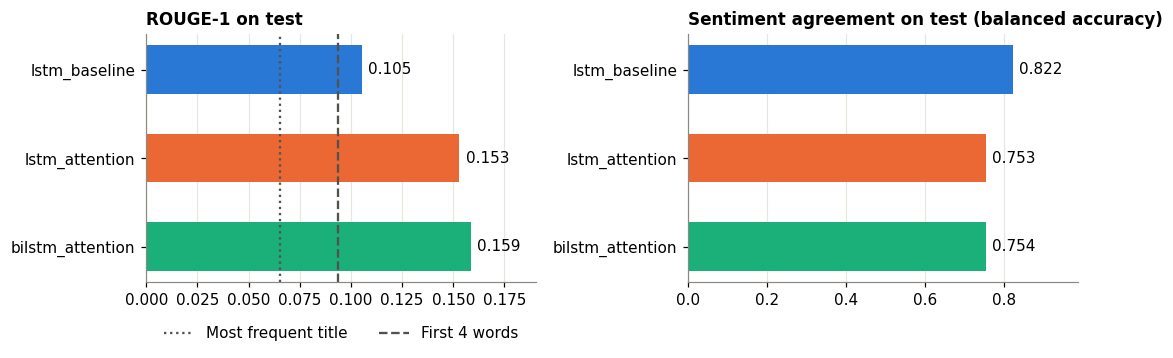

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
test_rows = results_df[(results_df.split == "test") & results_df.model.isin(MODEL_SPECS)].set_index("model").loc[list(MODEL_SPECS)]
for ax, metric, title in [(axes[0], "ROUGE-1", "ROUGE-1 on test"), (axes[1], "sentiment balanced acc", "Sentiment agreement on test (balanced accuracy)")]:
    values = test_rows[metric]
    bars = ax.barh(values.index[::-1], values.values[::-1], color=[COLORS[n] for n in values.index[::-1]], height=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set_title(title, loc="left")
    ax.set_xlim(0, max(values.max() * 1.2, 0.01))
    ax.grid(axis="y", visible=False)
references = results_df[(results_df.split == "test")]
for label, style in [("reference: most frequent title", ":"), ("reference: first 4 words", "--")]:
    value = references.loc[references.model == label, "ROUGE-1"].iloc[0]
    axes[0].axvline(value, color="#52514e", linestyle=style, linewidth=1.5, label=label.replace("reference: ", "").capitalize())
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout(); fig.savefig(FIG / "model_comparison.png"); plt.show()

### Decoding strategy: greedy versus beam search

The comparison is made on the selected model only.

In [23]:
rows = []
for split, frame in FRAMES.items():
    greedy = results_df[(results_df.split == split) & (results_df.model == BEST)].iloc[0].to_dict()
    predictions = generate_titles(models[BEST], LOADERS[split], "beam")
    summary, scores = evaluate_titles(predictions, frame)
    generated[(split, BEST, "beam")] = predictions
    per_example[(split, BEST, "beam")] = scores
    rows.append({k: greedy.get(k) for k in ["split", "decoding", "ROUGE-1", "ROUGE-2", "ROUGE-L", "BLEU-2", "BLEU-4", "exact match", "mean length", "distinct titles", "top title share", "sentiment balanced acc"]})
    rows.append({"split": split, "decoding": f"beam (k={CFG['beam_size']})", **{k: v for k, v in summary.items() if k != "sentiment agreement"}})
beam_df = pd.DataFrame(rows)
beam_df.to_csv(RES / "greedy_vs_beam.csv", index=False)
mean, low, high = paired_bootstrap(per_example[("test", BEST, "greedy")]["rouge1"], per_example[("test", BEST, "beam")]["rouge1"], CFG["n_bootstrap"], CFG["seed"])
print(f"Test ROUGE-1, beam minus greedy: {mean:+.4f} (95% CI {low:+.4f} to {high:+.4f})")
beam_df.round(3)

Test ROUGE-1, beam minus greedy: -0.0004 (95% CI -0.0041 to +0.0033)


,split,decoding,ROUGE-1,ROUGE-2,ROUGE-L,BLEU-2,BLEU-4,exact match,mean length,distinct titles,top title share,sentiment balanced acc
0,validation,greedy,0.150,0.037,0.148,5.681,2.220,0.015,3.029,0.225,0.107,0.772
1,validation,beam (k=5),0.152,0.044,0.150,6.364,2.599,0.018,3.088,0.169,0.069,0.765
2,test,greedy,0.159,0.043,0.156,6.108,2.195,0.018,3.037,0.231,0.112,0.754
3,test,beam (k=5),0.158,0.050,0.156,6.688,2.603,0.020,3.072,0.177,0.080,0.764


### Optional experiment: teacher-forcing ratio

Set `RUN_TF_EXPERIMENT = True` in section 1 to retrain the best model with a ratio of 0.5. The comparison uses generated-title metrics. Validation loss is measured under full teacher forcing, which naturally favours the model trained in those same conditions.

In [24]:
if RUN_TF_EXPERIMENT:
    tf_name = f"{BEST}_tf05"
    tf_model, tf_history = train_model(tf_name, MODEL_SPECS[BEST], 0.5)
    rows = []
    for label, model in [(f"teacher forcing {CFG['teacher_forcing']}", models[BEST]), ("teacher forcing 0.5", tf_model)]:
        summary, _ = evaluate_titles(generate_titles(model, val_loader), val_df)
        rows.append({"variant": label, **summary, **language_metrics(model, val_loader)})
    tf_df = pd.DataFrame(rows)
    tf_df.to_csv(RES / "teacher_forcing_experiment.csv", index=False)
    display(tf_df.round(3))
else:
    print("Teacher-forcing experiment skipped.")

Teacher-forcing experiment skipped.


## 9. Generated examples and error analysis

The examples below come from the test set, so the model never saw them during training. The objective is to explain **why** the model fails, not only to display its best outputs.

In [25]:
best_predictions = generated[("test", BEST, "greedy")]
baseline_predictions = generated[("test", "lstm_baseline", "greedy")]
top_generated = {t for t, _ in Counter(" ".join(p) for p in best_predictions).most_common(20)}

analysis = test_df[["Score", "polarity", "src_len", "Text", "Summary"]].copy()
analysis["reference"] = [" ".join(t) for t in test_df.tgt_tokens]
analysis["generated"] = [" ".join(p) for p in best_predictions]
analysis["baseline_generated"] = [" ".join(p) for p in baseline_predictions]
analysis = pd.concat([analysis, per_example[("test", BEST, "greedy")]], axis=1)
analysis["baseline_rouge1"] = per_example[("test", "lstm_baseline", "greedy")]["rouge1"].values
analysis["review_unk_rate"] = [np.mean([t not in src_vocab.stoi for t in s]) for s in test_df.src_tokens]
analysis["ref_has_oov"] = [any(t not in tgt_vocab.stoi for t in s) for s in test_df.tgt_tokens]
analysis["generic_output"] = analysis.generated.isin(top_generated)
analysis["pred_sentiment"] = sentiment_clf.predict(analysis.generated)
analysis["sentiment_flip"] = (analysis.polarity != "neutral") & (analysis.pred_sentiment != analysis.polarity)
analysis["repetition"] = [any(a == b for a, b in zip(p, p[1:])) for p in best_predictions]
analysis["no_overlap"] = analysis.rouge1 == 0
analysis.drop(columns=["Text"]).to_csv(RES / "test_predictions.csv", index=False)

def show(frame, n=10):
    columns = ["Score", "Text", "reference", "generated", "rouge1"]
    with pd.option_context("display.max_colwidth", 110):
        display(frame[columns].assign(Text=frame.Text.str.slice(0, 180)).head(n).round(2))

print("Reasonable matches: high overlap, non-generic output")
success = analysis[(analysis.rouge1 >= 0.5) & ~analysis.generic_output].sort_values("rouge1", ascending=False)
show(success.sample(min(10, len(success)), random_state=CFG["seed"]))

print("Failures: no overlap with the reference")
failures = analysis[analysis.no_overlap]
show(failures.sample(min(10, len(failures)), random_state=CFG["seed"]))

print("Sentiment flips: title contradicts the star rating")
flips = analysis[analysis.sentiment_flip]
show(flips.sample(min(10, len(flips)), random_state=CFG["seed"]))

print("Baseline versus best model on the same reviews")
with pd.option_context("display.max_colwidth", 80):
    display(analysis[["Text", "reference", "baseline_generated", "generated"]].assign(Text=analysis.Text.str.slice(0, 130)).sample(min(10, len(analysis)), random_state=CFG["seed"]))

selected = pd.concat([
    success.sample(min(15, len(success)), random_state=CFG["seed"]).assign(category="success"),
    failures.sample(min(15, len(failures)), random_state=CFG["seed"]).assign(category="no overlap"),
    flips.sample(min(15, len(flips)), random_state=CFG["seed"]).assign(category="sentiment flip"),
])
selected[["category", "Score", "Text", "reference", "generated", "baseline_generated", "rouge1"]].to_csv(RES / "selected_examples.csv", index=False)

Reasonable matches: high overlap, non-generic output


,Score,Text,reference,generated,rouge1
5558,5,"This is really good chocolate. While this is called a milk chocolate, it is 48% dark chocolate. That's a...",great chocolate,good chocolate,0.50
18,5,This is great stuff that my cats go crazy for - like it was catnip!! The container hleps to keep it fresh...,my cats soooo love this,my cats love this stuff,0.80
4581,5,my dogs absolutely love these things and go crazy! They leave the sweet potatoes and just eat the duck meat.,my dogs love these like crack cocaine lol,my dogs love these,0.67
2525,5,"These cookies are WONDERFUL! So happy to be able to enjoy a sweet, GF Snickerdoodle! The cookies are fla...",great cookies,great cookies,1.00
4031,5,This bacon cooker is the best I have come across so far.<br />Even my husband approves and he only would e...,best for cooking bacon,the best bacon ever,0.50
2891,5,"There aren't too many flavored decaf coffees, so I decided to try this one. It's very good & I'll probabl...",very good,good coffee,0.50
3019,3,The product is good. But I just realized that the price is more than double than other similar lychee. I b...,good product terrible price,good product,0.67
5394,5,This is the best commercial canned tuna I have ever gotten. They have canned it correctly and haven't cook...,great canned tuna,best canned tuna,0.67
381,5,"For any of you tea lovers out there, this brand of Chai has got to be the best. FORGET Starbucks! There ...",the world of chai,the best chai ever,0.50
5277,5,"Blended in my Magic Bullet, heated in the microwave on high for 1.5 minutes... oohh so delish... much bett...",better than hot chocolate,hot chocolate,0.67


Failures: no overlap with the reference


,Score,Text,reference,generated,rouge1
2197,5,"I'll admit it, I'm a bit of an almond addict. And Love N' Bake Almond Paste is the best out there, and is...",excellent almond paste with stellar results,best gf cookie mix,0.0
2833,5,I like a good cup of Joe every morning and this coffee makes it a great experience. French roast is one o...,would give it a 6 star,great coffee,0.0
396,5,"this product helped us emensly in giving our cat medicine. She loves them, and gobbles them up quick.",good news,cat food,0.0
5428,5,Ziyad brand rice and lentil pilaf (mujadara) is a delicious vegetarian side dish. It is a snap to make - ...,yummy and low sodium to boot,great rice,0.0
3765,5,"As another reviewer mentioned, this is a LOT of agar! Which is great, because I needed a lot for a 70-pers...",jello for vegetarians,great stuff,0.0
1365,4,Chances are if you are buying this you already know what hempseed tastes like. The price is good and the q...,not for everyone,great taste,0.0
1294,5,These guys rock! Nice refreshing drink with a little extra kick to help you wind down.I will reorder! Than...,nice refreshing and relaxing,great stuff,0.0
4487,5,I love Indian food and when I discovered Patak's cooking sauces it allowed me have delicious Indian food a...,delicious indian food at home with very little effort,best sauce ever,0.0
1252,5,Great flavor. Hard to find in stores now so this was a great way to continue buying this product.,sweet tooth,great flavor,0.0
5004,5,We enjoy our coffee and we are also picky about it's taste. This one for us is an all round pleaser. Great...,one of our favorites,great coffee,0.0


Sentiment flips: title contradicts the star rating


,Score,Text,reference,generated,rouge1
4273,4,I was a little hesitant to order these as I'm trying to avoid corn syrup and the company does not seem to ...,no corn syrup,not as good as i thought,0.00
257,2,"my bag was not very fresh at all,i have all gummy products and this is my only bad purchase,i love when it...",ok gummies,love these,0.00
1641,4,I have not been able to find a bun that was edible until I tried these. They are much better after being ...,pretty good hot dog buns,not as good as i remember,0.18
1535,1,"I sent this gift to friend of mine whom was recovering from surgery. The gift arrived, but the get well no...",who sent this gift,gift was a gift gift,0.22
1817,4,"Only issue is that it comes pre-sweetened too much, but if you like a coffee kick mixed with a sugar buzz....",taste but sweet,not a fan of coffee,0.00
1662,1,My dog has been eating a raw diet with Dr. Harveys pre mix. I bought this to try since reviews were good ...,dog won't eat it,dog loves it,0.50
4366,4,"Hodgson Mill makes high quality foods, however I was a bit frustrated to find that ""Medium"" is not the sam...",high quality but size is decieving,not what i expected,0.00
2848,5,I am so used to Tabasco that it is now tastes boring to me. I tried many kinds though; some are disappoint...,fresh taste flavorful,tastes like the real thing,0.25
2330,2,"I'm very VERY careful when it comes to putting food into my body. If it isn't natural, then it dosn't belo...",watch out these have hydrolyzed protein in them,not as good as they are the best,0.00
950,1,I ordered the Tassimo Coffee Maker and coffee discs for my daughter. I received the coffee in a timely ma...,have the coffee not the pot,great coffee,0.25


Baseline versus best model on the same reviews


,Text,reference,baseline_generated,generated
2794,"While waiting for my Amazon order to arrive, I bought a lemon-flavored stevi...",weak flavor in this water based item,good but not great,great tasting water
2592,I ordered three boxes for my british husbands bday. They called to tell me o...,good but amazon ripped me off,not what i expected,not the same as described
5356,"This Coca tea is nothing special. No extra energy or even aroma also, did no...",just another tea,not bad,great tea
2002,"These nut bars truly taste great, and the ""30% bigger"" size is just the righ...",delicious and well sized,great product,great tasting snack
4205,"A candy one cannot buy over the shelf, at least here anyway. Our children lo...",zagnut candy bars,great product,candy candy
553,Very happpy to find that Amazon is making this product available. I consider...,sugar twin,great product,great product
5260,I got these in hopes that I could replace some of my snacking habits with so...,possibilities just okay,not bad,i didn't like these beans
534,"I love this product. My family finished it within one week. It is so good, t...",very great product,great product,great product
5265,i like the tast of the tea..very fresh and calming. there's more tea in the...,very good,great coffee,good tea
5636,This is the essential ingredient for the spicy tofu dish that is a signature...,you need this for ma po tofu,good stuff,a little bit too sweet


,share of test reviews
No word in common with the reference,0.598
Among the 20 most frequent outputs (generic),0.387
Sentiment contradicts the rating,0.139
Immediately repeated word,0.011
Reference contains a word outside the vocabulary,0.204


Stars


,reviews,rouge1,generic,sentiment_flip
Score,,,,
1,547,0.098,0.393,0.389
2,286,0.088,0.469,0.413
3,454,0.107,0.392,0.000
4,866,0.153,0.359,0.201
5,3948,0.180,0.386,0.071


Review length


,reviews,rouge1,generic,sentiment_flip
review_length,,,,
up to 25,459,0.201,0.418,0.105
26-50,2031,0.180,0.428,0.100
51-80,1544,0.159,0.418,0.121
over 80 (truncated),2067,0.129,0.316,0.169


Review <UNK> rate


,reviews,rouge1,generic,sentiment_flip
unk_level,,,,
none,3669,0.171,0.401,0.117
up to 2%,1171,0.132,0.348,0.160
2-5%,1083,0.150,0.374,0.134
over 5%,178,0.140,0.438,0.146


Reference title length


,reviews,rouge1,generic,sentiment_flip
title_length,,,,
2,1536,0.175,0.430,0.109
3,1289,0.162,0.392,0.111
4-5,1908,0.164,0.367,0.124
6-10,1368,0.130,0.362,0.175


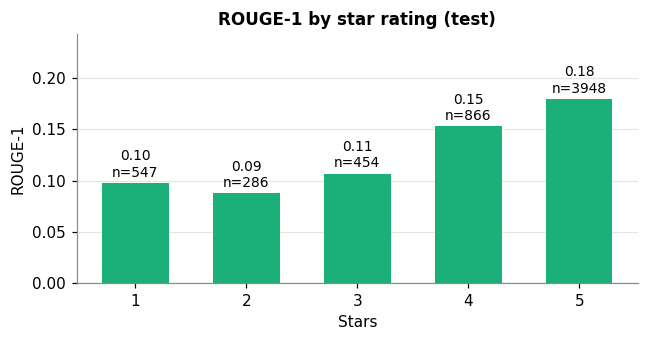

In [26]:
failure_summary = pd.Series({
    "No word in common with the reference": analysis.no_overlap.mean(),
    "Among the 20 most frequent outputs (generic)": analysis.generic_output.mean(),
    "Sentiment contradicts the rating": analysis.sentiment_flip.sum() / (analysis.polarity != "neutral").sum(),
    "Immediately repeated word": analysis.repetition.mean(),
    "Reference contains a word outside the vocabulary": analysis.ref_has_oov.mean(),
}, name="share of test reviews").round(3)
failure_summary.to_csv(RES / "failure_summary.csv")
display(failure_summary.to_frame())

def by_group(column, labels=None):
    table = analysis.groupby(column, observed=True).agg(reviews=("rouge1", "size"), rouge1=("rouge1", "mean"),
                                                       generic=("generic_output", "mean"), sentiment_flip=("sentiment_flip", "mean"))
    return table.round(3)

analysis["review_length"] = pd.cut(analysis.src_len, [0, 25, 50, 80, 10_000], labels=["up to 25", "26-50", "51-80", "over 80 (truncated)"])
analysis["unk_level"] = pd.cut(analysis.review_unk_rate, [-0.01, 0, 0.02, 0.05, 1], labels=["none", "up to 2%", "2-5%", "over 5%"])
analysis["title_length"] = pd.cut(test_df.tgt_len, [0, 2, 3, 5, 10], labels=["2", "3", "4-5", "6-10"])
groups = {"Stars": by_group("Score"), "Review length": by_group("review_length"),
          "Review <UNK> rate": by_group("unk_level"), "Reference title length": by_group("title_length")}
for label, table in groups.items():
    print(label); display(table)
pd.concat(groups).to_csv(RES / "error_by_group.csv")

fig, ax = plt.subplots(figsize=(6, 3.2))
stars = groups["Stars"]
ax.bar(stars.index.astype(str), stars.rouge1, color=COLORS.get(BEST, "#2a78d6"), width=0.6)
for x, (value, count) in enumerate(zip(stars.rouge1, stars.reviews)):
    ax.annotate(f"{value:.2f}\nn={count}", (x, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="ROUGE-1 by star rating (test)", xlabel="Stars", ylabel="ROUGE-1", ylim=(0, max(stars.rouge1.max() * 1.35, 0.01)))
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "rouge_by_stars.png"); plt.show()

### Attention maps

Each row is a generated word and each column a review word. A darker cell means the decoder gave that review word more weight while generating that title word.

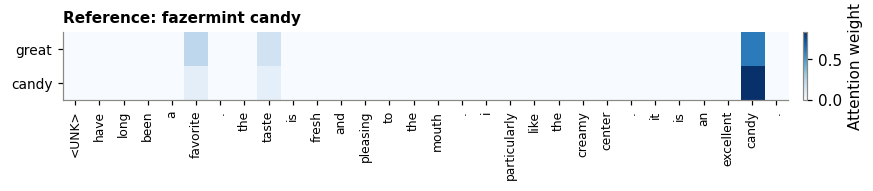

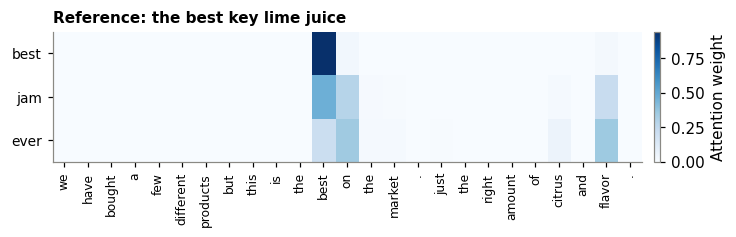

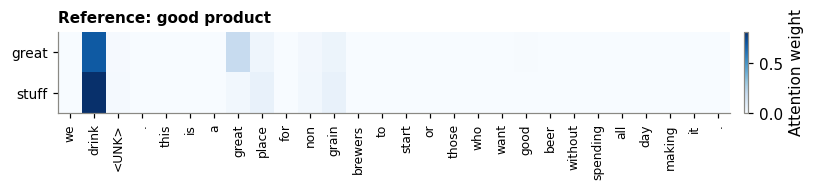

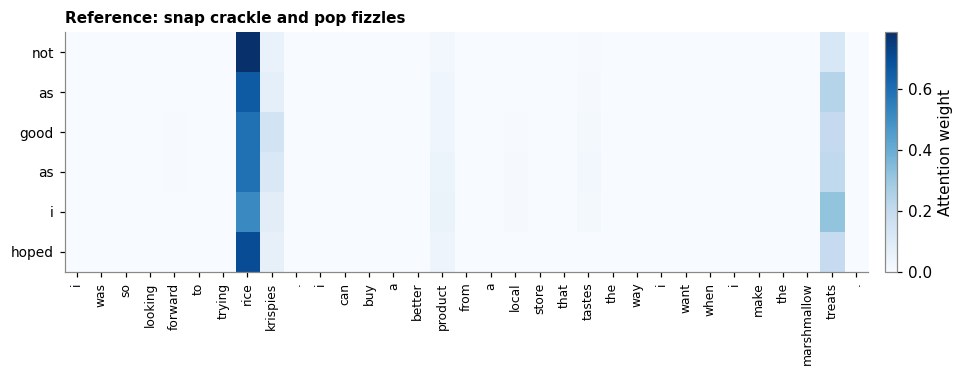

In [27]:
def plot_attention(model, row, path):
    ids = src_vocab.encode(row.src_tokens[:CFG["max_src_len"]])
    src = torch.tensor([ids], device=DEVICE)
    output, weights = greedy_batch(model, src, torch.tensor([len(ids)]), return_attention=True)
    title = tgt_vocab.decode(output[0].tolist())
    steps = max(len(title), 1)
    shown = min(len(ids), 35)  # first words only, for readability
    matrix = weights[0, :steps, :shown].detach().cpu().numpy()
    fig, ax = plt.subplots(figsize=(max(6, shown * 0.27), max(1.8, steps * 0.42 + 1)))
    image = ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(shown), [src_vocab.itos[i] for i in ids[:shown]], rotation=90, fontsize=8)
    ax.set_yticks(range(steps), title, fontsize=9)
    ax.grid(False)
    ax.set_title(f"Reference: {' '.join(row.tgt_tokens)}", loc="left", fontsize=10)
    fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label="Attention weight")
    fig.tight_layout(); fig.savefig(path); plt.show(); plt.close(fig)

attention_model_name = BEST if MODEL_SPECS[BEST]["use_attention"] else "lstm_attention"
candidates = analysis[(analysis.src_len.between(12, 35))]
pick = candidates[candidates.rouge1 > 0].sample(min(2, (candidates.rouge1 > 0).sum()), random_state=CFG["seed"]).index.tolist()
pick += candidates[candidates.rouge1 == 0].sample(min(2, (candidates.rouge1 == 0).sum()), random_state=CFG["seed"]).index.tolist()
for number, index in enumerate(pick, 1):
    plot_attention(models[attention_model_name], test_df.loc[index], FIG / f"attention_{number}.png")

### Titles for new reviews written by hand

In [28]:
custom_reviews = [
    "This coffee is smooth and rich with a hint of chocolate. I will definitely buy it again.",
    "The dog food arrived with a broken bag and my dog refused to eat it. Very disappointed.",
    "I expected these chips to be terrible but they are actually really tasty and not too salty.",
    "Not bad, but not great either. The flavor is fine but the price is too high for what you get.",
    "My kids love this cereal. It is healthy, crunchy and not too sweet.",
]
custom = pd.DataFrame({"review": custom_reviews})
for name, model in models.items():
    custom[name] = [generate_title(model, r) for r in custom_reviews]
custom[f"{BEST} (beam)"] = [generate_title(models[BEST], r, "beam") for r in custom_reviews]
custom.to_csv(RES / "custom_examples.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    display(custom)

,review,lstm_baseline,lstm_attention,bilstm_attention,bilstm_attention (beam)
0,This coffee is smooth and rich with a hint of chocolate. I will definitely buy it again.,great coffee,great coffee,great coffee,great coffee
1,The dog food arrived with a broken bag and my dog refused to eat it. Very disappointed.,not as good as the other mtr,dog likes it,dog food,dog food
2,I expected these chips to be terrible but they are actually really tasty and not too s...,not as good as the other mtr,tasty but not great,not bad,not bad
3,"Not bad, but not great either. The flavor is fine but the price is too high for what y...",not as good as the other mtr,not as good as i expected,not bad,ok but not great
4,"My kids love this cereal. It is healthy, crunchy and not too sweet.",great product,kids love it,my kids love this cereal,my kids love this cereal


### Manual annotation sheet

ROUGE penalises a good title that uses different words: "delicious coffee" versus "great taste" scores 0. To measure this, the sheet below contains 50 random test reviews. Mark `acceptable` as 1 or 0 by hand. The result gives a human estimate to set against ROUGE in the report.

In [29]:
sheet = analysis.sample(min(50, len(analysis)), random_state=CFG["seed"])[["Score", "Text", "reference", "generated", "rouge1"]].copy()
sheet["acceptable"] = ""
sheet.to_csv(RES / "manual_annotation_sheet.csv", index=False)

## 10. Export for the report

In [30]:
run_summary = {
    "config": CFG, "best_model": BEST, "device": str(DEVICE), "smoke_test": SMOKE_TEST,
    "parameters": param_counts,
    "epochs_trained": {n: len(h) for n, h in histories.items()},
    "best_epoch": {n: int(pd.DataFrame(h).val_loss.idxmin() + 1) for n, h in histories.items()},
    "seconds_per_epoch": {n: round(float(pd.DataFrame(h).seconds.mean()), 1) for n, h in histories.items()},
    "most_common_train_title": " ".join(MOST_COMMON_TITLE),
    "vocab_sizes": {"source": len(src_vocab), "target": len(tgt_vocab)},
    "torch_version": torch.__version__,
}
(RES / "run_summary.json").write_text(json.dumps(run_summary, indent=2))
(OUT / "vocabularies.json").write_text(json.dumps({"source": src_vocab.itos, "target": tgt_vocab.itos}))

archive = shutil.make_archive("nlp_project_results", "zip", OUT, "results")
archive_fig = shutil.make_archive("nlp_project_figures", "zip", OUT, "figures")
print(json.dumps(run_summary, indent=2))
print("\nDownload these two files for the report:", archive, archive_fig)

{
  "config": {
    "seed": 42,
    "n_samples": 60000,
    "min_src_tokens": 10,
    "max_src_tokens_filter": 200,
    "max_src_len": 80,
    "min_tgt_tokens": 2,
    "max_tgt_tokens": 10,
    "src_min_freq": 3,
    "tgt_min_freq": 3,
    "src_max_vocab": 20000,
    "tgt_max_vocab": 8000,
    "emb_dim": 128,
    "hidden_dim": 256,
    "n_layers": 1,
    "dropout": 0.3,
    "batch_size": 128,
    "epochs": 15,
    "patience": 3,
    "lr": 0.001,
    "clip": 1.0,
    "teacher_forcing": 1.0,
    "beam_size": 5,
    "beam_alpha": 0.7,
    "n_bootstrap": 1000
  },
  "best_model": "bilstm_attention",
  "device": "cuda",
  "smoke_test": false,
  "parameters": {
    "lstm_baseline": 4696694,
    "lstm_attention": 6757494,
    "bilstm_attention": 6626422
  },
  "epochs_trained": {
    "lstm_baseline": 15,
    "lstm_attention": 11,
    "bilstm_attention": 12
  },
  "best_epoch": {
    "lstm_baseline": 15,
    "lstm_attention": 8,
    "bilstm_attention": 9
  },
  "seconds_per_epoch": {
    "lstm

## 11. Baseline convergence check

Retrains the baseline with up to 30 epochs. Output: `results/baseline_convergence_output.txt`.

In [ ]:
# Convergence check: retrain the baseline with up to 30 epochs
CFG["epochs"] = 30
ext_name = "lstm_baseline_30ep"
ext_model, ext_history = train_model(ext_name, MODEL_SPECS["lstm_baseline"], CFG["teacher_forcing"])
h = pd.DataFrame(ext_history)
print("Epochs trained:", len(h), "| best epoch:", int(h.val_loss.idxmin() + 1), "| best val loss:", round(h.val_loss.min(), 3))

rows = []
for label, model in [("lstm_baseline (15 epochs)", models["lstm_baseline"]), (ext_name, ext_model), (BEST, models[BEST])]:
    predictions = generate_titles(model, test_loader)
    summary, scores = evaluate_titles(predictions, test_df)
    rows.append({"model": label, **summary, **language_metrics(model, test_loader)})
    if label == ext_name:
        ext_scores = scores
ext_df = pd.DataFrame(rows)
ext_df.to_csv(RES / "baseline_convergence_check.csv", index=False)
h.to_csv(RES / "baseline_30ep_history.csv", index=False)
print(ext_df.round(3).T.to_string())

for other in ["lstm_attention", "bilstm_attention"]:
    mean, low, high = paired_bootstrap(ext_scores.rouge1, per_example[("test", other, "greedy")]["rouge1"], CFG["n_bootstrap"], CFG["seed"])
    print(f"{other} minus {ext_name}, ROUGE-1: {mean:+.4f} (95% CI {low:+.4f} to {high:+.4f})")

examples = pd.DataFrame({"reference": analysis.reference, "generated": [" ".join(p) for p in generate_titles(ext_model, test_loader)]})
top = Counter(examples.generated).most_common(5)
print("Most frequent outputs:", top)


## 12. Hand-written tests

Output before the improvements: `results/hand_tests_before_improvements.txt`.

In [ ]:
# Try the models on your own reviews: edit this list and rerun the cell
my_reviews = {
    "positive": "This coffee is smooth and rich with a hint of chocolate. I will definitely buy it again.",
    "negative": "The dog food arrived with a broken bag and my dog refused to eat it. Very disappointed.",
    "negation": "This tea is not good at all. It tastes like nothing and I would not recommend it.",
    "contrast": "I expected these chips to be terrible but they are actually really tasty and not too salty.",
    "mixed": "The flavor is great, but the price is far too high for such a small box.",
    "neutral": "It's okay. Not bad, not great, just an average cereal.",
    "very short": "Love this honey, so good!",
    "rare words": "This Ethiopian yirgacheffe has wonderful floral and bergamot notes.",
    "out of domain": "The laptop screen stopped working after two days and customer service never replied.",
}

model_names = list(models)
for label, review in my_reviews.items():
    print(f"[{label}] {review}")
    known = tokenize_source(review)
    unknown = [t for t in known if t not in src_vocab.stoi]
    print("  unknown words:", ", ".join(unknown) if unknown else "none")
    for name in model_names:
        print(f"  {name:<18}: {generate_title(models[name], review)}")
    print(f"  {BEST + ' (beam)':<18}: {generate_title(models[BEST], review, 'beam')}")
    print()

# Random reviews from the test set, with the title written by the author
print("=" * 80, "\nRandom test reviews\n")
for _, row in test_df.sample(8).iterrows():
    print(f"[{row.Score} stars] {row.Text[:200]}")
    print(f"  reference         : {' '.join(row.tgt_tokens)}")
    for name in model_names:
        print(f"  {name:<18}: {generate_title(models[name], row.Text)}")
    print()


## 13. Improvements based on the failure analysis

Output: `results/improvement_run_output.txt`.

In [ ]:
# Section 12. Improvements motivated by the failure analysis.
# Each variant changes one thing compared with bilstm_attention. Validation and test sets are unchanged.
#   balanced  : negative reviews are sampled more often   -> reversed sentiment on negative reviews
#   copy      : pointer-generator, can copy review words  -> product names outside the title vocabulary
#   more_data : 150,000 training reviews instead of about 48,000 -> overfitting, stock phrases
#   combined  : the three changes together
from torch.utils.data import WeightedRandomSampler

IMP_EPOCHS = 15
LARGE_TRAIN_SIZE = 150_000
IMP_DIR = RES / "improvements"
IMP_DIR.mkdir(exist_ok=True)
V = len(tgt_vocab)

# ---------- 1. Larger training set: same vocabularies, no product or text shared with validation/test ----------
pool = raw.dropna(subset=["Text", "Summary"]).copy()
pool["norm_text"] = pool["Text"].map(normalize)
pool = pool.drop_duplicates("norm_text")
held_products = set(val_df.ProductId) | set(test_df.ProductId)
known_texts = set(pd.concat([train_df, val_df, test_df]).Text.map(normalize))
pool = pool[~pool.ProductId.isin(held_products) & ~pool.norm_text.isin(known_texts)]
pool["src_len"] = pool["Text"].map(lambda t: len(tokenize_source(t)))
pool["tgt_len"] = pool["Summary"].map(lambda t: len(tokenize_target(t)))
pool = pool[pool.src_len.between(CFG["min_src_tokens"], CFG["max_src_tokens_filter"])
            & pool.tgt_len.between(CFG["min_tgt_tokens"], CFG["max_tgt_tokens"])]
extra = pool.sample(min(max(LARGE_TRAIN_SIZE - len(train_df), 0), len(pool)), random_state=CFG["seed"]).drop(columns="norm_text")
extra["src_tokens"] = extra["Text"].map(tokenize_source)
extra["tgt_tokens"] = extra["Summary"].map(tokenize_target)
extra["polarity"] = extra["Score"].map(polarity)
large_train_df = pd.concat([train_df, extra], ignore_index=True)
assert not set(large_train_df.ProductId) & held_products
print(f"Training reviews: {len(train_df):,} -> {len(large_train_df):,}")
del pool

# ---------- 2. Pointer-generator (See et al., 2017) ----------
class CopyDataset(Dataset):
    # Extended IDs: title vocabulary, then the words of this review that are outside it
    def __init__(self, frame):
        self.items = []
        for src_tokens, tgt_tokens in zip(frame.src_tokens, frame.tgt_tokens):
            src_tokens = src_tokens[:CFG["max_src_len"]]
            oovs, ext = [], []
            for token in src_tokens:
                if token in ".,!?":
                    ext.append(PAD)  # punctuation cannot be copied into a title
                elif token in tgt_vocab.stoi:
                    ext.append(tgt_vocab.stoi[token])
                else:
                    if token not in oovs:
                        oovs.append(token)
                    ext.append(V + oovs.index(token))
            tgt = [SOS]
            for token in tgt_tokens:
                if token in tgt_vocab.stoi:
                    tgt.append(tgt_vocab.stoi[token])
                else:
                    tgt.append(V + oovs.index(token) if token in oovs else UNK)
            tgt.append(EOS)
            self.items.append((torch.tensor(src_vocab.encode(src_tokens)), torch.tensor(ext), torch.tensor(tgt), oovs))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

def copy_collate(batch):
    src, ext, tgt, oovs = zip(*batch)
    return (pad_sequence(src, batch_first=True, padding_value=PAD), pad_sequence(ext, batch_first=True, padding_value=PAD),
            torch.tensor([len(s) for s in src]), pad_sequence(tgt, batch_first=True, padding_value=PAD),
            list(oovs), max(len(o) for o in oovs))

class CopySeq2Seq(Seq2Seq):
    def __init__(self):
        super().__init__(bidirectional=True, use_attention=True)
        self.p_gen = nn.Linear(CFG["hidden_dim"] * 2 + CFG["emb_dim"], 1)

    def copy_step(self, previous, state, memory, mask, src_ext, max_oov):
        previous = previous.masked_fill(previous >= V, UNK)  # a copied word enters the decoder as <UNK>
        decoder = self.decoder
        embedded = decoder.dropout(decoder.embedding(previous))
        context, weights = decoder.attention(state[0][-1], memory, mask)
        output, state = decoder.rnn(torch.cat([embedded, context], dim=-1).unsqueeze(1), state)
        features = torch.cat([output.squeeze(1), context, embedded], dim=-1)
        generate = torch.sigmoid(self.p_gen(features))
        vocab_probs = torch.softmax(decoder.out(decoder.dropout(features)), dim=-1) * generate
        probs = torch.cat([vocab_probs, torch.zeros(src_ext.size(0), max_oov, device=src_ext.device)], dim=-1)
        probs = probs.scatter_add(1, src_ext, (1 - generate) * weights)
        return torch.log(probs + 1e-12), state, weights

    def copy_forward(self, src, src_ext, lengths, tgt, max_oov):
        memory, mask, state = self.encode(src, lengths)
        log_probs = []
        for t in range(tgt.size(1) - 1):
            step_log_probs, state, _ = self.copy_step(tgt[:, t], state, memory, mask, src_ext, max_oov)
            log_probs.append(step_log_probs)
        return torch.stack(log_probs, dim=1)

# ---------- 3. Generic training and generation ----------
def batch_loss(model, batch):
    if isinstance(model, CopySeq2Seq):
        src, ext, lengths, tgt, _, max_oov = batch
        src, ext, tgt = src.to(DEVICE), ext.to(DEVICE), tgt.to(DEVICE)
        log_probs = model.copy_forward(src, ext, lengths, tgt, max_oov)
        target = tgt[:, 1:]
        loss = nn.functional.nll_loss(log_probs.reshape(-1, log_probs.size(-1)), target.reshape(-1), ignore_index=PAD, reduction="sum")
    else:
        src, lengths, tgt = batch
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        logits = model(src, lengths, tgt, 1.0)
        target = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, logits.size(-1)), target.reshape(-1))
    return loss, (target != PAD).sum().item()

def mean_loss(model, data_loader):
    model.eval()
    total, tokens = 0.0, 0
    with torch.no_grad():
        for batch in data_loader:
            loss, count = batch_loss(model, batch)
            total += loss.item(); tokens += count
    return total / tokens

def fit_variant(name, model, train_data, val_data):
    path = CKPT / f"{name}.pt"
    settings = hashlib.md5(json.dumps([CFG_HASH, IMP_EPOCHS, len(train_data.dataset)]).encode()).hexdigest()[:10]
    if path.exists() and not FORCE_RETRAIN:
        saved = torch.load(path, map_location=DEVICE)
        if saved.get("cfg_hash") == settings:
            model.load_state_dict(saved["state"])
            print(f"{name}: reusing existing checkpoint")
            return model, saved["history"]
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)
    history, best, stale, best_state = [], float("inf"), 0, None
    print(f"\n=== {name} | {count_parameters(model):,} parameters | {len(train_data.dataset):,} reviews ===")
    for epoch in range(1, IMP_EPOCHS + 1):
        start, total, tokens = time.time(), 0.0, 0
        model.train()
        for batch in train_data:
            loss, count = batch_loss(model, batch)
            optimizer.zero_grad()
            (loss / count).backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG["clip"])
            optimizer.step()
            total += loss.item(); tokens += count
        val_loss = mean_loss(model, val_data)
        scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": total / tokens, "val_loss": val_loss, "seconds": time.time() - start})
        print(f"epoch {epoch:2d} | train {total / tokens:.3f} | val {val_loss:.3f} | {time.time() - start:.0f}s")
        if val_loss < best:
            best, stale = val_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= CFG["patience"]:
                print(f"Early stopping at epoch {epoch}")
                break
    model.load_state_dict(best_state)
    torch.save({"state": best_state, "history": history, "cfg_hash": settings}, path)
    return model, history

@torch.no_grad()
def copy_titles(model, data_loader):
    model.eval()
    titles = []
    for src, ext, lengths, _, oovs, max_oov in data_loader:
        src, ext = src.to(DEVICE), ext.to(DEVICE)
        memory, mask, state = model.encode(src, lengths)
        previous = torch.full((src.size(0),), SOS, device=DEVICE)
        outputs = []
        for t in range(MAX_GEN_LEN):
            log_probs, state, _ = model.copy_step(previous, state, memory, mask, ext, max_oov)
            log_probs[:, FORBIDDEN] = float("-inf")
            if t == 0:
                log_probs[:, EOS] = float("-inf")
            previous = log_probs.argmax(-1)
            outputs.append(previous)
        for row, row_oovs in zip(torch.stack(outputs, dim=1).tolist(), oovs):
            words = []
            for i in row:
                if i == EOS:
                    break
                if i >= V:
                    if i - V < len(row_oovs):
                        words.append(row_oovs[i - V])
                else:
                    words.append(tgt_vocab.itos[i])
            titles.append(words)
    return titles

def titles_for(model, frame):
    if isinstance(model, CopySeq2Seq):
        return copy_titles(model, DataLoader(CopyDataset(frame), batch_size=CFG["batch_size"], collate_fn=copy_collate))
    return generate_titles(model, loader(frame))

def title_for_text(model, text):
    frame = pd.DataFrame({"src_tokens": [tokenize_source(text)], "tgt_tokens": [["x"]]})
    return " ".join(titles_for(model, frame)[0])

# ---------- 4. Training ----------
def balanced_sampler(frame):
    counts = frame.polarity.value_counts()
    weights = frame.polarity.map(lambda p: 1 / math.sqrt(counts[p])).to_numpy(dtype=float, copy=True)  # milder than full balancing
    return WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), num_samples=len(frame), replacement=True)

def make_train_loader(frame, use_copy, use_balance):
    dataset = CopyDataset(frame) if use_copy else TitleDataset(frame)
    return DataLoader(dataset, batch_size=CFG["batch_size"], collate_fn=copy_collate if use_copy else collate,
                      shuffle=not use_balance, sampler=balanced_sampler(frame) if use_balance else None)

copy_val_loader = DataLoader(CopyDataset(val_df), batch_size=CFG["batch_size"], collate_fn=copy_collate)
copy_test_loader = DataLoader(CopyDataset(test_df), batch_size=CFG["batch_size"], collate_fn=copy_collate)

VARIANTS = {
    "imp_balanced": {"copy": False, "balance": True, "frame": train_df},
    "imp_copy": {"copy": True, "balance": False, "frame": train_df},
    "imp_more_data": {"copy": False, "balance": False, "frame": large_train_df},
    "imp_combined": {"copy": True, "balance": True, "frame": large_train_df},
}

def summarize(name, model, history, label):
    rows = []
    for split, frame in FRAMES.items():
        predictions = titles_for(model, frame)
        summary, scores = evaluate_titles(predictions, frame)
        negative = (frame.polarity == "negative").values
        predicted = sentiment_clf.predict([" ".join(p) for p, n in zip(predictions, negative) if n])
        ref_oov = np.array([any(t not in tgt_vocab.stoi for t in s) for s in frame.tgt_tokens])
        best_epoch = pd.DataFrame(history).val_loss.idxmin() + 1 if history else None
        rows.append({"split": split, "variant": label, **summary,
                     "negative titled positive": float((predicted == "positive").mean()),
                     "uses word outside title vocab": float(np.mean([any(w not in tgt_vocab.stoi for w in p) for p in predictions])),
                     "ROUGE-1, refs with unknown word": scores.rouge1.values[ref_oov].mean(),
                     "best epoch": best_epoch, "epochs run": len(history) if history else None,
                     "seconds per epoch": round(float(pd.DataFrame(history).seconds.mean()), 1) if history else None})
        per_example[(split, name, "greedy")] = scores
        generated[(split, name, "greedy")] = predictions
    return rows

imp_models = {}
imp_rows = summarize("bilstm_attention", models["bilstm_attention"], histories["bilstm_attention"], "bilstm_attention (reference)")

for name, spec in VARIANTS.items():
    set_seed(CFG["seed"])
    model = (CopySeq2Seq() if spec["copy"] else Seq2Seq(**MODEL_SPECS["bilstm_attention"])).to(DEVICE)
    model, history = fit_variant(name, model, make_train_loader(spec["frame"], spec["copy"], spec["balance"]),
                                 copy_val_loader if spec["copy"] else val_loader)
    imp_models[name] = model
    pd.DataFrame(history).assign(variant=name).to_csv(IMP_DIR / f"history_{name}.csv", index=False)
    imp_rows += summarize(name, model, history, name)
    pd.DataFrame(imp_rows).to_csv(IMP_DIR / "improvement_metrics.csv", index=False)  # saved after each model

# ---------- 5. Results ----------
imp_df = pd.DataFrame(imp_rows)
show_columns = ["variant", "ROUGE-1", "ROUGE-2", "BLEU-2", "exact match", "distinct titles", "top title share", "sentiment balanced acc",
                "negative titled positive", "uses word outside title vocab", "ROUGE-1, refs with unknown word", "mean length",
                "best epoch", "epochs run", "seconds per epoch"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
validation_rows = imp_df[imp_df.split == "validation"]
print("\nVALIDATION (use this table to choose)\n", validation_rows[show_columns].round(3).T.to_string())
IMP_BEST = validation_rows.loc[validation_rows["ROUGE-1"].idxmax(), "variant"]
print("\nBest on validation ROUGE-1:", IMP_BEST)
print("\nTEST (final report only)\n", imp_df[imp_df.split == "test"][show_columns].round(3).T.to_string())

rows = []
for name in VARIANTS:
    for metric in ["rouge1", "rouge2"]:
        mean, low, high = paired_bootstrap(per_example[("test", "bilstm_attention", "greedy")][metric],
                                           per_example[("test", name, "greedy")][metric], CFG["n_bootstrap"], CFG["seed"])
        rows.append({"variant minus bilstm_attention": name, "metric": metric, "difference": round(mean, 4),
                     "CI 2.5%": round(low, 4), "CI 97.5%": round(high, 4), "CI excludes 0": low > 0 or high < 0})
imp_boot = pd.DataFrame(rows)
imp_boot.to_csv(IMP_DIR / "improvement_bootstrap.csv", index=False)
print("\n", imp_boot.to_string())

# ---------- 6. The same hand-written tests ----------
imp_tests = {
    "positive": "This coffee is smooth and rich with a hint of chocolate. I will definitely buy it again.",
    "negative": "The dog food arrived with a broken bag and my dog refused to eat it. Very disappointed.",
    "negation": "This tea is not good at all. It tastes like nothing and I would not recommend it.",
    "contrast": "I expected these chips to be terrible but they are actually really tasty and not too salty.",
    "mixed": "The flavor is great, but the price is far too high for such a small box.",
    "neutral": "It's okay. Not bad, not great, just an average cereal.",
    "very short": "Love this honey, so good!",
    "rare words": "This Ethiopian yirgacheffe has wonderful floral and bergamot notes.",
    "out of domain": "The laptop screen stopped working after two days and customer service never replied.",
}
test_rows = []
for label, review in imp_tests.items():
    print(f"\n[{label}] {review}")
    print(f"  {'bilstm_attention':<18}: {title_for_text(models['bilstm_attention'], review)}")
    row = {"case": label, "review": review, "bilstm_attention": title_for_text(models["bilstm_attention"], review)}
    for name, model in imp_models.items():
        row[name] = title_for_text(model, review)
        print(f"  {name:<18}: {row[name]}")
    test_rows.append(row)
pd.DataFrame(test_rows).to_csv(IMP_DIR / "improvement_hand_tests.csv", index=False)

print("\n" + "=" * 80 + "\nTest reviews whose reference contains a word outside the title vocabulary\n")
sample_index = [i for i, s in enumerate(test_df.tgt_tokens) if any(t not in tgt_vocab.stoi for t in s)]
for i in pd.Series(sample_index).sample(min(8, len(sample_index)), random_state=CFG["seed"]):
    row = test_df.iloc[i]
    print(f"[{row.Score} stars] {row.Text[:160]}")
    print(f"  reference         : {' '.join(row.tgt_tokens)}")
    print(f"  bilstm_attention  : {' '.join(generated[('test', 'bilstm_attention', 'greedy')][i])}")
    for name in VARIANTS:
        print(f"  {name:<18}: {' '.join(generated[('test', name, 'greedy')][i])}")
    print()

shutil.make_archive("nlp_project_results", "zip", OUT, "results")
print("Results zip updated: nlp_project_results.zip")


## 14. Export for the animated demo

Writes `demo_traces.json` and the files used by the live demo.

In [ ]:
# Section 13. Export the real decoding steps of the final model for the animated demo
DEMO_MODEL = imp_models["imp_combined"]
DEMO_MODEL.eval()

def demo_word(i, oovs):
    if i >= V:
        return oovs[i - V]
    return tgt_vocab.itos[i]

@torch.no_grad()
def trace_review(model, tokens):
    tokens = tokens[:CFG["max_src_len"]]
    dataset = CopyDataset(pd.DataFrame({"src_tokens": [tokens], "tgt_tokens": [["x"]]}))
    src, ext, lengths, _, oov_lists, max_oov = copy_collate([dataset[0]])
    src, ext = src.to(DEVICE), ext.to(DEVICE)
    oovs = oov_lists[0]
    memory, mask, state = model.encode(src, lengths)
    half = memory.size(-1) // 2
    # A few real values of each encoder state, forward and backward parts
    encoder_view = {"forward": memory[0, :, :12].cpu().numpy().round(2).tolist(),
                    "backward": memory[0, :, half:half + 12].cpu().numpy().round(2).tolist()}
    decoder = model.decoder
    previous = torch.tensor([SOS], device=DEVICE)
    steps, title = [], []
    for t in range(MAX_GEN_LEN):
        input_word = "<SOS>" if t == 0 else demo_word(previous.item(), oovs)
        decoder_input = previous.masked_fill(previous >= V, UNK)
        embedded = decoder.embedding(decoder_input)
        context, weights = decoder.attention(state[0][-1], memory, mask)
        output, state = decoder.rnn(torch.cat([embedded, context], dim=-1).unsqueeze(1), state)
        features = torch.cat([output.squeeze(1), context, embedded], dim=-1)
        generate = torch.sigmoid(model.p_gen(features))
        generated_part = torch.softmax(decoder.out(features), dim=-1) * generate
        generated_part = torch.cat([generated_part, torch.zeros(1, max_oov, device=DEVICE)], dim=-1)
        copied_part = torch.zeros_like(generated_part).scatter_add(1, ext, (1 - generate) * weights)
        total = generated_part + copied_part
        total[:, FORBIDDEN] = -1.0
        if t == 0:
            total[:, EOS] = -1.0
        values, indices = total[0].topk(5)
        chosen = indices[0].item()
        steps.append({
            "input": input_word,
            "input_as_unk": bool(previous.item() >= V),
            "attention": weights[0].cpu().numpy().round(3).tolist(),
            "p_gen": round(generate.item(), 3),
            "top": [{"word": demo_word(i, oovs), "prob": round(v, 4), "generated": round(generated_part[0, i].item(), 4),
                     "copied": round(copied_part[0, i].item(), 4), "in_title_vocab": i < V}
                    for i, v in zip(indices.tolist(), values.tolist())],
            "chosen": demo_word(chosen, oovs),
        })
        previous = indices[:1]
        if chosen == EOS:
            break
        title.append(demo_word(chosen, oovs))
    return {"tokens": tokens, "ids": src[0].tolist(), "is_unk": [t not in src_vocab.stoi for t in tokens],
            "encoder": encoder_view, "steps": steps, "title": " ".join(title)}

demo_hand = {
    "Clear and positive": "This coffee is smooth and rich with a hint of chocolate. I will definitely buy it again.",
    "Short": "Love this honey, so good!",
    "Negative": "The dog food arrived with a broken bag and my dog refused to eat it. Very disappointed.",
    "Negation": "This tea is not good at all. It tastes like nothing and I would not recommend it.",
    "Contrast": "I expected these chips to be terrible but they are actually really tasty and not too salty.",
    "Mixed": "The flavor is great, but the price is far too high for such a small box.",
    "Neutral": "It's okay. Not bad, not great, just an average cereal.",
    "Rare words": "This Ethiopian yirgacheffe has wonderful floral and bergamot notes.",
    "Outside the domain": "The laptop screen stopped working after two days and customer service never replied.",
}

# Test reviews: picked by a fixed rule, including failures. Short enough to read on screen.
demo_scores = per_example[("test", "imp_combined", "greedy")]
demo_frame = test_df.assign(rouge1=demo_scores.rouge1.values)
short = demo_frame[demo_frame.src_len.between(12, 45)]
picks = [("Test set: good overlap", short[short.rouge1 >= 0.5], 3),
         ("Test set: no overlap", short[short.rouge1 == 0], 2),
         ("Test set: negative review", short[short.polarity == "negative"], 2)]

traces = []
for label, review in demo_hand.items():
    trace = trace_review(DEMO_MODEL, tokenize_source(review))
    trace.update(label=label, text=review, source="hand", stars=None, reference=None)
    traces.append(trace)
used = set()
for label, frame, count in picks:
    frame = frame[~frame.index.isin(used)]
    for index, row in frame.sample(min(count, len(frame)), random_state=CFG["seed"]).iterrows():
        used.add(index)
        trace = trace_review(DEMO_MODEL, row.src_tokens)
        trace.update(label=label, text=html.unescape(TAG_RE.sub(" ", row.Text)), source="test", stars=int(row.Score),
                     reference=" ".join(row.tgt_tokens))
        traces.append(trace)

for trace in traces:
    frame = pd.DataFrame({"src_tokens": [trace["tokens"]], "tgt_tokens": [["x"]]})
    assert trace["title"] == " ".join(titles_for(DEMO_MODEL, frame)[0]), "trace differs from the model's greedy output"
    trace["others"] = {"LSTM baseline": " ".join(titles_for(models["lstm_baseline"], frame)[0]),
                       "BiLSTM + attention": " ".join(titles_for(models["bilstm_attention"], frame)[0])}

demo_export = {"model": "imp_combined", "reviews": traces}
Path("demo_traces.json").write_text(json.dumps(demo_export, ensure_ascii=False, separators=(",", ":")))

# Keep what the live demo will need if the session closes
demo_dir = Path("demo_files")
demo_dir.mkdir(exist_ok=True)
shutil.copy("demo_traces.json", demo_dir)
shutil.copy(CKPT / "imp_combined.pt", demo_dir)
(demo_dir / "vocabularies.json").write_text(json.dumps({"source": src_vocab.itos, "target": tgt_vocab.itos}))
(demo_dir / "demo_config.json").write_text(json.dumps(CFG))
shutil.make_archive("nlp_demo_files", "zip", demo_dir)

print(f"{len(traces)} reviews exported, all identical to the model's greedy output")
print("demo_traces.json:", round(os.path.getsize("demo_traces.json") / 1024), "KB")
print("nlp_demo_files.zip:", round(os.path.getsize("nlp_demo_files.zip") / 1024 / 1024), "MB")
for trace in traces:
    print(f"  [{trace['label']}] {trace['title']}")
